# 02 · Liquidation Activity & Features
How does short-window liquidation activity differ from its recent background, and what is available at decision time?

Historical tables come from the original quality, burst and follow-through experiments.
A small artificial-feed calculation below demonstrates the working feature pipeline.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists())
sys.path.insert(0, str(ROOT/'src'))
sys.path.insert(0, str(ROOT))
from research_paths import artifact_dir
import research_report as report
report.style()
def show(fig, name):
    path=ROOT/'artifacts/figures'/name
    fig.savefig(path, dpi=150)
    display(Image(filename=str(path)))
    plt.close(fig)

## Counts, notional and burst detection
The main detector compares a completed 5-second interval with the preceding 1,200 seconds (240 disjoint bins).
Windows are half-open: `[t − window, t)`. Counts and `price × amount` notional are separate signals.
Calibration ends on December 15; price/trade confirmations define potential cascades, not independent price predictions.

In [2]:
config=json.loads((artifact_dir('bursts')/'frozen_config.json').read_text())
display(pd.Series(config,name='frozen value').to_frame())
thresholds=report.table('bursts','thresholds.csv')
display(thresholds.loc[thresholds.window_s.eq(5)])
classes=report.table('bursts','classification_summary.csv')
display(classes.groupby(['symbol','phase'])[['active_windows','burst_windows','potential_cascade_windows']].sum())

,frozen value
version,2026-10-11-bursts-v1
observation_window_s,5
baseline_s,1200
calibration_start,2025-12-01 00:00:00+00:00
threshold_freeze,2025-12-15 00:00:00+00:00
validation_start,2026-02-01 00:00:00+00:00
interval,"[t-window,t)"
ratio_threshold,5
absolute_floor_quantile,0.900000
minimum_trade_ratio,2


,symbol,exchange,side,window_s,calibration_active_windows,count_p50,count_p90,...,notional_p99,minimum_count,minimum_notional,ratio_threshold,historical_quantile,minimum_consecutive_windows,frozen_at_timestamp
4,btcusdt,binance,buy,5,5590,1.000000,3.000000,...,"205,699.542619",3,"29,002.047450",5.000000,0.990000,2,1765756800000000
5,btcusdt,binance,sell,5,6803,1.000000,3.000000,...,"238,604.553244",3,"27,585.327440",5.000000,0.990000,2,1765756800000000
6,btcusdt,bybit,buy,5,2470,2.000000,11.000000,...,"1,091,262.654865",11,"125,253.046960",5.000000,0.990000,2,1765756800000000
7,btcusdt,bybit,sell,5,3201,2.000000,14.000000,...,"1,685,339.691300",14,"158,655.999000",5.000000,0.990000,2,1765756800000000
16,ethusdt,binance,buy,5,7160,1.000000,3.000000,...,"209,236.557455",3,"25,000.000000",5.000000,0.990000,2,1765756800000000
17,ethusdt,binance,sell,5,7841,1.000000,3.000000,...,"247,476.798300",3,"25,000.000000",5.000000,0.990000,2,1765756800000000
18,ethusdt,bybit,buy,5,2420,1.000000,9.000000,...,"740,526.186093",9,"93,883.429290",5.000000,0.990000,2,1765756800000000
19,ethusdt,bybit,sell,5,3206,2.000000,9.000000,...,"1,037,581.098140",9,"120,085.942850",5.000000,0.990000,2,1765756800000000


active_windows  burst_windows  potential_cascade_windows
symbol  phase                                                               
btcusdt train                45588           1492                         50
        validation           49275           1605                         37
ethusdt train                50798           1594                         51
        validation           50634           1374                         19

## Distributions from the full audit
Histogram bins and counts are extracted from the original exact audit summaries.
The signed `log10(1 + abs(x))` transform is unchanged; liquidation notional here is positive.
These are aggregate distributions over all dates, not a newly sampled subset.

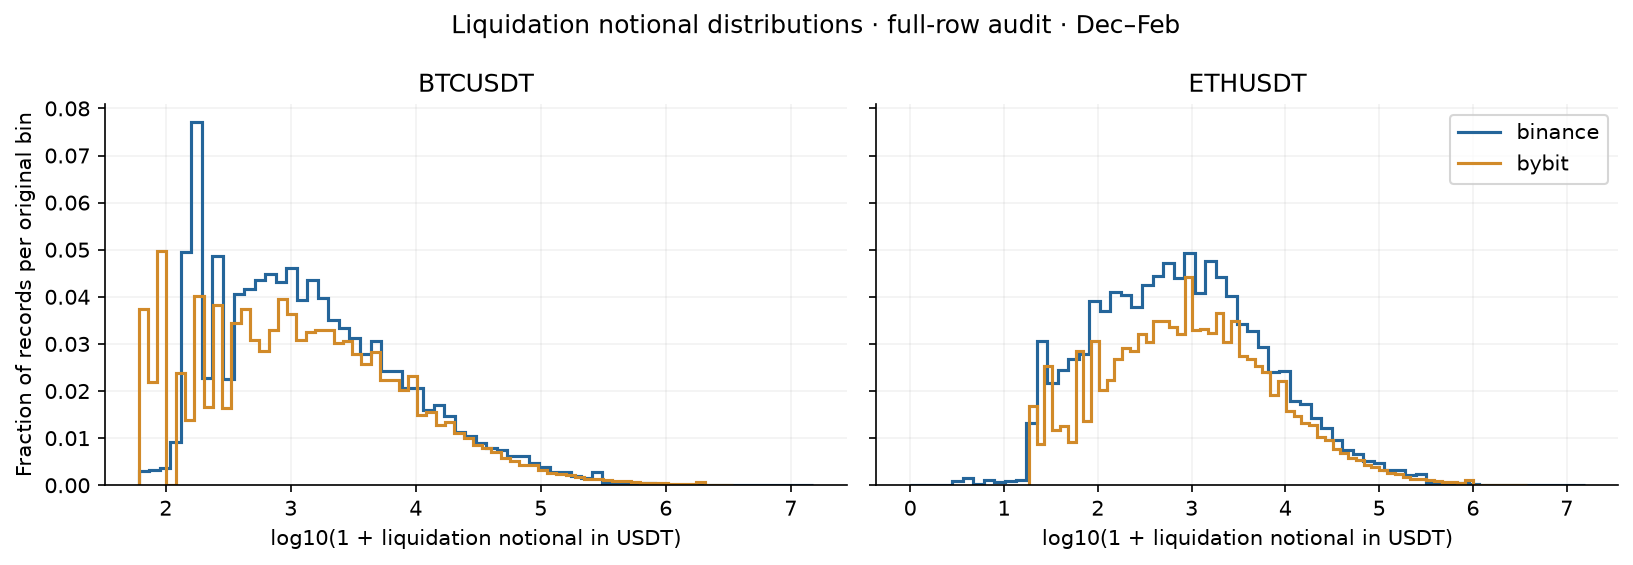

In [3]:
show(report.liquidation_distribution_figure(),'liquidation_notional.png')

## Causal feature construction
Maker market state is held for one second, using records strictly before that second boundary.
The 5-second liquidation alignment is additionally computed at the exact trade timestamp.
Bybit timestamps receive the 200 ms delay once, inside `liquidation_arrays`.
Features include book imbalance/spread, lagged returns, volatility, trade flow, liquidation ages/counts/notional,
intensity ratios and acceleration. No future midpoint or label is allowed into the feature schema.

In [4]:
from maker_hybrid.core import liquidation_arrays, liquidation_window
from maker_hybrid.submission import market_batches
from maker_hybrid.features import trade_features, feature_columns
sample=ROOT/'data/sample'
tr=pd.read_csv(sample/'binance_trades/perp_btcusdt.csv')
bb=pd.read_csv(sample/'binance_booktickers/perp_btcusdt.csv')
bn=pd.read_csv(sample/'binance_liquidations/perp_btcusdt.csv')
by=pd.read_csv(sample/'bybit_liquidations/btcusdt.csv')
batch=next(market_batches(tr,bb,bn,by,'btcusdt'))
x=trade_features(batch[2],batch[4])
display(x[['second','spread_bps','book_imbalance','return_5s_bps','rv_20s_bps',
           'liq_binance_buy_log_count_5s','liq_binance_buy_log_notional_5s','alignment']].tail(6))
print('E3 feature count:',len(feature_columns('E3')))

,second,spread_bps,book_imbalance,return_5s_bps,rv_20s_bps,liq_binance_buy_log_count_5s,liq_binance_buy_log_notional_5s,alignment
1795,1767227395,0.200000,-0.367418,1.334092,1.999431,0.000000,0.000000,0
1796,1767227396,0.200000,-0.187236,1.582987,1.897058,0.000000,0.000000,0
1797,1767227397,0.200000,0.542201,1.450333,1.902897,0.000000,0.000000,0
1798,1767227398,0.200000,0.471099,1.616251,1.771897,0.000000,0.000000,0
1799,1767227399,0.200000,-0.016378,1.822086,1.763132,0.000000,0.000000,0
1800,1767227400,0.200000,0.461128,1.150149,1.736769,0.000000,0.000000,0


E3 feature count: 81


## Window sensitivity and follow-through
Alternative window lengths and offsets are retained in `sensitivity.csv`. Post-episode returns are descriptive:
the episode end is retrospective. They must not be fed back into a feature that claims to be known at onset.

In [5]:
sensitivity=report.table('bursts','sensitivity.csv')
display(sensitivity.query("phase=='validation' and event_type=='all_bursts'"))
follow=report.table('followthrough','price_summary.csv').query(
    "phase=='validation' and side=='ALL' and horizon_s==20 and anchor=='episode_end'")
display(follow[['symbol','classification','valid','mean_post_signed_return_bps','reversal_share',
                'signed_mean_ci95_low','signed_mean_ci95_high']])

,window_s,baseline_s,offset_s,variant,phase,event_type,episodes,reference_episodes,reference_match_share,alternative_match_share,flagged_duration_s,minimum_persistence_s
2,2,600,0,primary,validation,all_bursts,3504,2677,0.753455,0.642694,"7,818.000000",10
6,2,1200,0,primary,validation,all_bursts,3661,2677,0.765409,0.638896,"8,274.000000",10
10,2,2400,0,primary,validation,all_bursts,3798,2677,0.767277,0.623223,"8,630.000000",10
14,5,600,0,primary,validation,all_bursts,2574,2677,0.935749,0.967754,"14,080.000000",10
18,5,1200,0,primary,validation,all_bursts,2677,2677,1.000000,1.000000,"14,895.000000",10
22,5,2400,0,primary,validation,all_bursts,2799,2677,0.975346,0.942479,"15,750.000000",10
26,10,600,0,primary,validation,all_bursts,1189,2677,0.458722,0.920101,"13,090.000000",20
30,10,1200,0,primary,validation,all_bursts,1241,2677,0.480388,0.930701,"13,890.000000",20
34,10,2400,0,primary,validation,all_bursts,1305,2677,0.494583,0.919540,"14,950.000000",20
38,5,1200,2,primary,validation,all_bursts,2712,2677,0.721703,0.714602,"15,170.000000",10


,symbol,classification,valid,mean_post_signed_return_bps,reversal_share,signed_mean_ci95_low,signed_mean_ci95_high
123,btcusdt,Liquidation burst,1387,-1.178688,0.537130,-1.985457,-0.310186
141,btcusdt,Normal activity,30299,-0.465658,0.538500,-0.600449,-0.327610
165,btcusdt,Potential liquidation cascade,30,-6.121407,0.666667,-14.082945,0.153136
183,ethusdt,Liquidation burst,1243,-2.470106,0.573612,-3.691232,-1.319722
201,ethusdt,Normal activity,32438,-0.725732,0.554473,-0.945694,-0.451008
225,ethusdt,Potential liquidation cascade,17,-12.367617,0.705882,-27.633143,6.403555


Negative signed post-end returns describe reversals relative to the liquidation side.
Selection on cascade price/volume and overlapping episodes limits interpretation.
The follow-through statistical tables apply Holm adjustment across 42 tests; post-cascade return patterns do not
survive that adjustment. This is not evidence for a tradable post-end rule.

## Conclusion
The detector and causal maker features are implemented. The distinction between an available event,
a retrospective episode label and a future maker markout is essential. Next, test burst prediction separately
before using predicted probabilities as maker features.